# Step 1: Building the Player-Game Dataset

**Goal of this notebook:** turn raw play-by-play data into a table with **one row per player per game**. Each row has:

- a **label**: did this player score an anytime touchdown (ATTD) in this game? (1 = yes, 0 = no)
- **features**: numbers we would *already know on the Wednesday before the game*, that might help predict the label

That table is what every model in Step 2 will learn from.

### What you'll learn here
1. **The unit of prediction.** Your first notebook predicted *season totals* for QBs (about 70 training rows). Predicting *games* gives us tens of thousands of rows, and it matches the question a sportsbook asks.
2. **Feature engineering.** Raw plays don't predict anything on their own. We summarise them into signals like "red-zone carries per game over the last 3 games".
3. **Data leakage.** This is the #1 way ML projects fool themselves. Any feature that uses information from the game we're predicting is cheating. We'll build every feature so that it only looks backwards, and then *prove* to ourselves why that matters.

## 1. Load the data

We only need ~30 of the 372 play-by-play columns, so we pass `usecols`. That makes loading much faster and uses far less memory. It also fixes the `DtypeWarning` you saw in your first notebook, because the mixed-type columns aren't loaded at all.

We also load **rosters** from nflverse. Play-by-play doesn't tell you a player's position, and we need positions to keep only QB/RB/WR/TE. The roster files came from `https://github.com/nflverse/nflverse-data/releases/tag/rosters`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)

SEASONS = [2023, 2024, 2025]

PBP_COLS = [
    "game_id", "season", "season_type", "week", "game_date",
    "home_team", "away_team", "posteam", "defteam",
    "play_type", "two_point_attempt", "yardline_100",
    "passer_player_id", "rusher_player_id", "receiver_player_id",
    "rushing_yards", "receiving_yards", "complete_pass",
    "touchdown", "td_player_id", "td_team",
    "spread_line", "total_line",
]

pbp = pd.concat(
    [pd.read_csv(f"../data/play_by_play_{s}.csv", usecols=PBP_COLS, low_memory=False) for s in SEASONS],
    ignore_index=True,
)

rosters = pd.concat(
    [pd.read_csv(f"../data/roster_{s}.csv", usecols=["season", "gsis_id", "full_name", "position"]) for s in SEASONS],
    ignore_index=True,
)

print("Plays:", pbp.shape)
print("Roster rows:", rosters.shape)
pbp.groupby(["season", "season_type"]).week.agg(["min", "max", "nunique"])

Plays: (129579, 23)
Roster rows: (9443, 4)


min  max  nunique
season season_type                   
2023   POST          19   22        4
       REG            1   18       18
2024   POST          19   22        4
       REG            1   18       18
2025   REG            1   12       12

Notice that **2025 only goes through week 12**. That's fine: it's our "live" season, and it's what we'll test on in Step 2.

We'll keep regular season **and** playoffs, because both are games a sportsbook offers ATTD bets on.

## 2. Define the label: "scored an anytime touchdown"

At sportsbooks, an ATTD bet wins if the player **scores** a touchdown: rushing, receiving, or a return. **Throwing** a TD pass does *not* count. So Patrick Mahomes throwing 4 TDs is still a losing ATTD bet unless he runs one in.

nflverse makes this easy: on every touchdown play, `td_player_id` is the player who actually *scored*. On a passing TD that is the receiver, not the QB. So:

> **label = 1 if the player appears as `td_player_id` in that game, else 0**

This is also a fix to your first notebook. There, `touchdown` was summed over every play a QB threw, which counted **pick-sixes returned against him** as his touchdowns.

In [2]:
tds = (
    pbp.loc[pbp["touchdown"] == 1, ["game_id", "td_player_id"]]
    .dropna()
    .groupby(["game_id", "td_player_id"]).size()
    .rename("tds").reset_index()
    .rename(columns={"td_player_id": "player_id"})
)
print("Player-games with at least one TD:", len(tds))
tds.head()

Player-games with at least one TD: 3211


,game_id,player_id,tds
0,2023_01_ARI_WAS,00-0037077,1
1,2023_01_ARI_WAS,00-0037746,1
2,2023_01_ARI_WAS,00-0037815,1
3,2023_01_BUF_NYJ,00-0031588,1
4,2023_01_BUF_NYJ,00-0037740,1


## 3. Count each player's opportunities per game

Touchdowns come from **opportunities**: carries and targets, especially close to the end zone. For every player in every game we count:

| column | meaning |
|---|---|
| `carries` | rushing attempts (including QB scrambles) |
| `targets` | times a pass was thrown to them |
| `rz_carries`, `rz_targets` | carries/targets inside the opponent's 20 (the **red zone**) |
| `gl_carries` | carries inside the 5 (the **goal line**), the single best TD signal for RBs and QBs |
| `ez_targets` | targets inside the 10 |
| `rush_yards`, `rec_yards`, `receptions` | volume and efficiency |
| `pass_att` | dropbacks with a pass thrown (so a QB who never runs still counts as playing) |

`yardline_100` is the distance to the opponent's end zone, so "inside the 20" means `yardline_100 <= 20`.

We drop two-point attempts (they aren't touchdowns) and `no_play` rows (penalties wipe them out).

In [3]:
plays = pbp[pbp["play_type"].isin(["run", "pass"]) & (pbp["two_point_attempt"] == 0)].copy()
plays["rz"] = plays["yardline_100"] <= 20
plays["inside10"] = plays["yardline_100"] <= 10
plays["gl"] = plays["yardline_100"] <= 5

GAME_KEYS = ["game_id", "season", "week", "game_date", "posteam", "defteam"]

rush = (
    plays.dropna(subset=["rusher_player_id"])
    .groupby(GAME_KEYS + ["rusher_player_id"])
    .agg(carries=("rz", "size"), rz_carries=("rz", "sum"), gl_carries=("gl", "sum"),
         rush_yards=("rushing_yards", "sum"))
    .reset_index().rename(columns={"rusher_player_id": "player_id"})
)

rec = (
    plays.dropna(subset=["receiver_player_id"])
    .groupby(GAME_KEYS + ["receiver_player_id"])
    .agg(targets=("rz", "size"), rz_targets=("rz", "sum"), ez_targets=("inside10", "sum"),
         receptions=("complete_pass", "sum"), rec_yards=("receiving_yards", "sum"))
    .reset_index().rename(columns={"receiver_player_id": "player_id"})
)

passing = (
    plays.dropna(subset=["passer_player_id"])
    .groupby(GAME_KEYS + ["passer_player_id"])
    .agg(pass_att=("rz", "size"))
    .reset_index().rename(columns={"passer_player_id": "player_id"})
)

pg = rush.merge(rec, on=GAME_KEYS + ["player_id"], how="outer")
pg = pg.merge(passing, on=GAME_KEYS + ["player_id"], how="outer")
count_cols = ["pass_att", "carries", "rz_carries", "gl_carries", "rush_yards",
              "targets", "rz_targets", "ez_targets", "receptions", "rec_yards"]
pg[count_cols] = pg[count_cols].fillna(0)
pg.head()

,game_id,season,week,game_date,posteam,defteam,player_id,carries,rz_carries,gl_carries,rush_yards,targets,rz_targets,ez_targets,receptions,rec_yards,pass_att
0,2023_01_ARI_WAS,2023,1,2023-09-10,ARI,WAS,00-0030061,0.0,0.0,0.0,0.0,10.0,2.0,0.0,6.0,21.0,0.0
1,2023_01_ARI_WAS,2023,1,2023-09-10,ARI,WAS,00-0033251,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,2023_01_ARI_WAS,2023,1,2023-09-10,ARI,WAS,00-0033553,14.0,0.0,0.0,62.0,5.0,1.0,0.0,5.0,8.0,0.0
3,2023_01_ARI_WAS,2023,1,2023-09-10,ARI,WAS,00-0033949,3.0,1.0,0.0,-3.0,0.0,0.0,0.0,0.0,0.0,33.0
4,2023_01_ARI_WAS,2023,1,2023-09-10,ARI,WAS,00-0035662,1.0,0.0,0.0,29.0,5.0,1.0,0.0,3.0,28.0,0.0


### Who counts as "playing" in a game?

We keep any player with **at least one carry, target, or pass attempt**. That's a small simplification. A player can be active and touch the ball zero times, and that ATTD bet would still lose. Most books *void* bets on inactive players, though, so "was involved in at least one play" is a reasonable stand-in for "was a live bet". We can revisit it later.

Now we attach the label and the position, keeping only QB/RB/WR/TE. Fullbacks get folded into RB.

In [4]:
pg = pg.merge(tds, on=["game_id", "player_id"], how="left")
pg["tds"] = pg["tds"].fillna(0).astype(int)
pg["scored"] = (pg["tds"] > 0).astype(int)

pos = rosters.dropna(subset=["gsis_id"]).drop_duplicates(["season", "gsis_id"])
pos = pos.rename(columns={"gsis_id": "player_id", "full_name": "player"})
pos["position"] = pos["position"].replace({"FB": "RB"})

pg = pg.merge(pos, on=["season", "player_id"], how="left")
print("Position counts before filtering:")
print(pg["position"].value_counts(dropna=False).head(10))

pg = pg[pg["position"].isin(["QB", "RB", "WR", "TE"])].copy()
print("\nPlayer-games kept:", len(pg))

Position counts before filtering:
position
WR    5943
RB    3858
TE    2967
QB    1787
P       26
DB      24
OL      18
LB      10
DL       2
Name: count, dtype: int64

Player-games kept: 14555


## 4. The base rate, and why "75% accurate" is a trap

Before building anything, always ask: **how often does the thing I'm predicting happen?** That's the *base rate*.

In [5]:
print(f"Overall: {pg['scored'].mean():.1%} of player-games include a TD\n")
pg.groupby("position")["scored"].agg(rate="mean", games="size").sort_values("rate", ascending=False)

Overall: 20.8% of player-games include a TD



,rate,games
position,,
RB,0.261016,3858
WR,0.214370,5943
TE,0.164139,2967
QB,0.147174,1787


Only about **1 in 5** player-games has a TD. So a "model" that always says **"no touchdown"** is right about 80% of the time, which beats 75%, while being completely useless for betting.

This is called **class imbalance**, and it's why we will judge models in Step 2 with:
- **Log loss / Brier score.** These measure how good the *probabilities* are, not just yes/no.
- **Calibration.** When the model says 40%, does it happen ~40% of the time?
- **Edge vs. the sportsbook** (Step 3). Are we better than the odds?

Keep this table in mind. It's the bar every model has to beat.

## 5. Game context: Vegas lines and the team's implied total

Sportsbooks already publish a very smart prediction of how many points each team will score. `total_line` is the expected combined score. `spread_line` is how many points the **home** team is favoured by (positive = home favourite). From those two numbers we can get each team's **implied points**:

$$\text{home implied} = \frac{\text{total} + \text{spread}}{2}, \qquad \text{away implied} = \frac{\text{total} - \text{spread}}{2}$$

More expected points means more expected touchdowns, for everyone on that team. Lines are posted well before Wednesday, so this is fair to use.

*Caveat:* the play-by-play file stores the **closing** line (from kickoff), which moves a little after Wednesday. It's a small, known leak we'll accept for now and note in the README.

In [6]:
games = pbp[["game_id", "home_team", "away_team", "spread_line", "total_line"]].drop_duplicates("game_id")
pg = pg.merge(games, on="game_id", how="left")

pg["is_home"] = (pg["posteam"] == pg["home_team"]).astype(int)
pg["implied_total"] = np.where(
    pg["is_home"] == 1,
    (pg["total_line"] + pg["spread_line"]) / 2,
    (pg["total_line"] - pg["spread_line"]) / 2,
)
pg = pg.drop(columns=["home_team", "away_team"])

# Does it matter? TD rate by implied-total bucket:
pg.groupby(pd.cut(pg["implied_total"], [0, 18, 21, 24, 27, 40]), observed=True)["scored"].mean()

implied_total
(0, 18]     0.153312
(18, 21]    0.178725
(21, 24]    0.208606
(24, 27]    0.247033
(27, 40]    0.295110
Name: scored, dtype: float64

Players on teams expected to score 27+ points find the end zone far more often than players on teams expected to score under 18. That's a strong, simple feature.

## 6. Team shares: how big is this player's slice of the pie?

Raw counts can mislead. Eight targets on a team that throws 25 times is a bigger role than eight targets on a team that throws 45 times. So we also compute each player's **share** of the team's carries, targets, and red-zone opportunities.

In [7]:
team = (
    plays.groupby(["game_id", "posteam"])
    .agg(team_carries=("rusher_player_id", "count"),
         team_targets=("receiver_player_id", "count"),
         team_rz_opps=("rz", "sum"))
    .reset_index()
)
pg = pg.merge(team, on=["game_id", "posteam"], how="left")
pg["rz_opps"] = pg["rz_carries"] + pg["rz_targets"]

## 7. The most important cell: features that only look backwards

Here's the rule: **to predict game *g*, a feature may only use games before *g*.**

The tool for this is `groupby(player).shift(1)`. It slides every value down one row, so the row for game *g* sees the stats from game *g−1*. Then `.rolling(n)` averages the last *n* of those.

```
game:          1    2    3    4
carries:      12   18   15   20
shift(1):    NaN   12   18   15      <- what we knew going into each game
rolling(3):  NaN   12   15   15      <- average of up to 3 previous games
```

We sort each player's games by date, and the rolling window **carries across seasons**. A player's week 1 features in 2024 come from the end of 2023. A brand-new player (a rookie in week 1) has no history, so their features are `NaN`. The model in Step 2 will have to handle that, which is part of the lesson there.

We build two windows:
- **last 3 games**: recent role (catches injuries, depth-chart changes)
- **last 8 games**: stable baseline (less noisy)

In [8]:
pg = pg.sort_values(["player_id", "game_date", "game_id"]).reset_index(drop=True)

ROLL_STATS = ["carries", "targets", "rz_carries", "rz_targets", "gl_carries", "ez_targets",
              "rush_yards", "rec_yards", "scored", "tds"]

g = pg.groupby("player_id", sort=False)
for n in (3, 8):
    for col in ROLL_STATS:
        pg[f"{col}_l{n}"] = g[col].transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())

# Shares over the last 8 games: sum of player's opps / sum of team's opps
def prior_sum(df, col, n=8):
    return df.groupby("player_id", sort=False)[col].transform(lambda s: s.shift(1).rolling(n, min_periods=1).sum())

pg["carry_share_l8"]  = prior_sum(pg, "carries")  / prior_sum(pg, "team_carries")
pg["target_share_l8"] = prior_sum(pg, "targets")  / prior_sum(pg, "team_targets")
pg["rz_share_l8"]     = prior_sum(pg, "rz_opps")  / prior_sum(pg, "team_rz_opps")

# Long-run touchdown rate (all prior games) and experience
pg["td_rate_career"] = g["scored"].transform(lambda s: s.shift(1).expanding().mean())
pg["games_prior"] = g.cumcount()

pg[["player", "game_date", "carries", "carries_l3", "scored", "scored_l8", "games_prior"]].head(10)

,player,game_date,carries,carries_l3,scored,scored_l8,games_prior
0,Aaron Rodgers,2023-09-11,0.0,NaN,0,NaN,0
1,Aaron Rodgers,2024-09-09,0.0,0.000000,0,0.0,1
2,Aaron Rodgers,2024-09-15,1.0,0.000000,0,0.0,2
3,Aaron Rodgers,2024-09-19,3.0,0.333333,0,0.0,3
4,Aaron Rodgers,2024-09-29,5.0,1.333333,0,0.0,4
5,Aaron Rodgers,2024-10-06,0.0,3.000000,0,0.0,5
6,Aaron Rodgers,2024-10-14,0.0,2.666667,0,0.0,6
7,Aaron Rodgers,2024-10-20,0.0,1.666667,0,0.0,7
8,Aaron Rodgers,2024-10-27,0.0,0.000000,0,0.0,8
9,Aaron Rodgers,2024-10-31,0.0,0.000000,0,0.0,9


Look at the first rows. `carries_l3` on each row equals the average of the **previous** rows' `carries`, never including its own. That's what "no leakage" looks like in practice.

## 8. Opponent defense: who gives up touchdowns to this position?

Some defenses get run on; others get beat by tight ends. For each defense we count how many touchdowns it allowed **to each position** per game, then take the same backwards-looking rolling average over its last 8 games.

In [9]:
def_pos = (
    pg.groupby(["defteam", "game_id", "game_date", "position"])["scored"].sum()
    .unstack("position", fill_value=0).stack().rename("td_allowed").reset_index()
    .sort_values(["defteam", "position", "game_date", "game_id"])
)
def_pos["opp_td_allowed_pos_l8"] = (
    def_pos.groupby(["defteam", "position"])["td_allowed"]
    .transform(lambda s: s.shift(1).rolling(8, min_periods=1).mean())
)
pg = pg.merge(def_pos[["defteam", "game_id", "position", "opp_td_allowed_pos_l8"]],
              on=["defteam", "game_id", "position"], how="left")
pg.groupby("position")["opp_td_allowed_pos_l8"].describe()[["mean", "min", "max"]]

,mean,min,max
position,,,
QB,0.178368,0.0,1.000
RB,0.668438,0.0,2.000
TE,0.316159,0.0,1.250
WR,0.851058,0.0,2.125


## 9. Proving why leakage matters

Here's an experiment you should do once and then never forget. Compare the **same-game** red-zone carries (leaky, because we only know them *after* the game) with the **prior-games** version we built:

In [10]:
rb = pg[pg["position"] == "RB"]
print("RB TD rate by red-zone carries IN THE SAME GAME (leaky!):")
print(rb.groupby(rb["rz_carries"].clip(upper=4))["scored"].mean().round(2), "\n")

print("RB TD rate by AVERAGE red-zone carries over the PREVIOUS 3 games (honest):")
print(rb.groupby(pd.cut(rb["rz_carries_l3"], [-0.01, 0.5, 1.5, 2.5, 99]), observed=True)["scored"].mean().round(2))

RB TD rate by red-zone carries IN THE SAME GAME (leaky!):
rz_carries
0.0    0.06
1.0    0.21
2.0    0.43
3.0    0.49
4.0    0.68
Name: scored, dtype: float64 

RB TD rate by AVERAGE red-zone carries over the PREVIOUS 3 games (honest):
rz_carries_l3
(-0.01, 0.5]    0.14
(0.5, 1.5]      0.21
(1.5, 2.5]      0.36
(2.5, 99.0]     0.48
Name: scored, dtype: float64


The leaky version looks amazing: RBs with 4+ red-zone carries score most of the time. A model trained on it would look brilliant in testing and then be **useless on Wednesday**, because you don't know Sunday's red-zone carries on Wednesday.

The honest version still shows a clear trend. It's weaker, but it's *real*. Most "my model is 95% accurate!" posts online have a bug like this somewhere.

## 10. A first look: which features relate to scoring?

Point-biserial correlation (just Pearson correlation against a 0/1 label) gives a quick, rough ranking. It's not the final word, because it only sees straight-line relationships one feature at a time. It's a good sanity check, though.

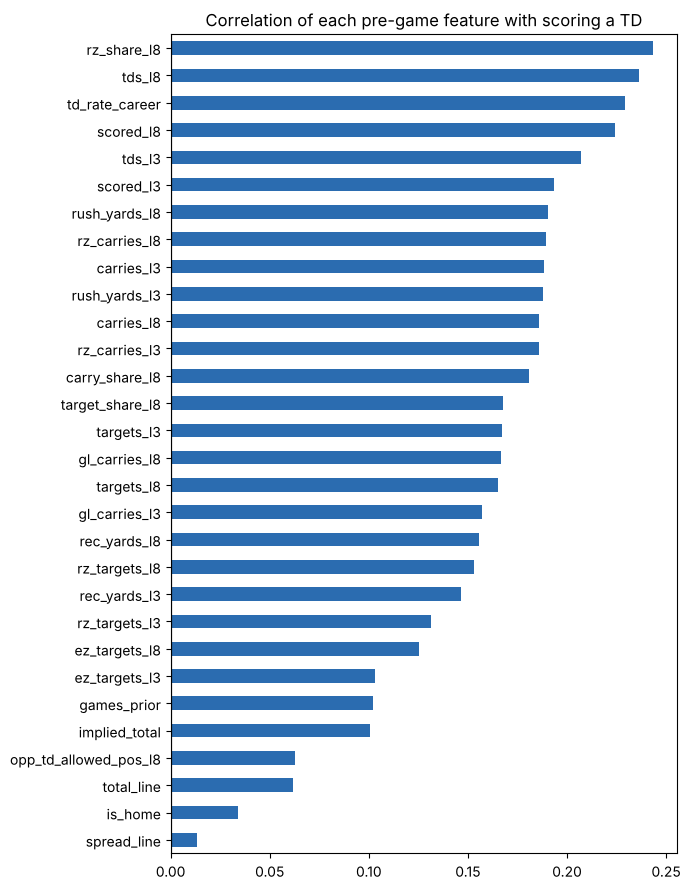

In [11]:
FEATURES = (
    [f"{c}_l{n}" for n in (3, 8) for c in ROLL_STATS]
    + ["carry_share_l8", "target_share_l8", "rz_share_l8", "td_rate_career", "games_prior",
       "implied_total", "spread_line", "total_line", "is_home", "opp_td_allowed_pos_l8"]
)

corr = pg[FEATURES + ["scored"]].corr()["scored"].drop("scored").sort_values()
plt.figure(figsize=(7, 9))
corr.plot.barh(color=np.where(corr > 0, "#2b6cb0", "#c05621"))
plt.title("Correlation of each pre-game feature with scoring a TD")
plt.axvline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

The red-zone and goal-line features near the top are what football intuition says. TDs come from opportunities close to the end zone.

## 11. Save the dataset

We save to Parquet, a compressed column format that's much smaller and faster than CSV and keeps the dtypes. Step 2 starts by loading this file.

In [12]:
ID_COLS = ["game_id", "season", "week", "game_date", "player_id", "player", "position", "posteam", "defteam"]
LABEL_COLS = ["scored", "tds"]

out = pg[ID_COLS + LABEL_COLS + FEATURES].sort_values(["game_date", "game_id", "posteam", "player"]).reset_index(drop=True)
out.to_parquet("../data/player_games.parquet", index=False)

print("Saved", out.shape, "->", "data/player_games.parquet")
print("Rows per season:", out.groupby("season").size().to_dict())
print("Features:", len(FEATURES))

Saved (14555, 41) -> data/player_games.parquet
Rows per season: {2023: 5591, 2024: 5520, 2025: 3444}
Features: 30


## Recap

- We changed the unit of prediction from *QB-season* to **player-game**, which gave us tens of thousands of rows instead of ~70.
- The label is **"scored a rushing, receiving, or return TD"**, matching how ATTD bets are settled.
- About **20%** of player-games have a TD, so raw accuracy is a misleading metric.
- Every feature uses **only past games** (`shift(1)` then `rolling`), plus Vegas lines known before kickoff.
- We saw how a leaky feature makes a model look far better than it really is.

**Next (Step 2):** train a baseline, a logistic regression, and LightGBM on 2023–2024, test them week by week on 2025, and learn log loss and calibration curves.

## Try this

1. Add a **last-1-game** window (`n = 1`) to the rolling loop. Does `rz_carries_l1` correlate more or less with `scored` than `rz_carries_l3`? Why might the longer window be better?
2. Find the 10 players with the highest `rz_share_l8` in the most recent week. Do the names match who you'd bet on?
3. *(Harder)* QBs score TDs mostly by running. Add a feature for **designed QB runs vs. scrambles** (hint: the `qb_scramble` column). Is one more predictive than the other?